# C06 — NEW + Steps 2–4 versus historical Step 4 on frozen C05 Ghostbuster

**NEW = the 54 saved U04 M75 texts.** Run in a fresh kernel after shutting down Llama/Qwen evaluation kernels.
This notebook performs no generation, detector fitting, feature selection, or threshold tuning.

1. Verify all 54 NEW inputs and historical Step 4 counterparts.
2. Apply the accepted C02w0 downstream engine: sentence means plus conditional repair; gated punctuation; exclamation handling; hyphen repair.
3. Score NEW + Step 4 with C05's frozen model, normalization, seven manual + seven selected symbolic features.
4. Reproduce C05's historical Step 4 scores/staircase, then plot both systems together at identical human-calibrated thresholds.

**Resume:** rerun all cells. Completed editing stages and per-document probability streams are atomic checkpoints. An interrupted stage/document restarts; completed stages/documents are reused. All 54 texts, including generation-token-capped inputs, are retained. An unfilled target is recorded, not treated as a failed run.

**References:** historical per-case training reference IDs/bounds and the original punctuation gate are retained. Human training prose is used only to reconstruct existing aggregate statistics and the generic compound inventory; it is never inserted into a rewrite or passed to the local edit scorer. Matched subject-specific human text is not used by the editing stage.

Outputs: `results/causal/C06_NEW_step4_Ghostbuster_v1/`; figures also export to `figures/`.


In [1]:
from pathlib import Path
import ast, copy, gc, hashlib, json, math, os, re, sys, tempfile, time, contextlib, fcntl, subprocess
from collections import Counter
from functools import lru_cache
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import spacy, transformers
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents,
    Path.home()/'Downloads/TemporalContextResearch/reproduction']
    if (p/'results/causal/C05_Ghostbuster_RAID_fixed54/ghostbuster_frozen.pkl').exists()), None)
assert ROOT is not None, 'Set ROOT to the reproduction directory containing saved C05 artifacts.'
BASE = ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
PARENT = ROOT/'results/causal/C02r_discovery_gated_punctuation'
C05 = ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
OUT = ROOT/'results/causal/C06_NEW_step4_Ghostbuster_v1'
FIG = ROOT/'figures'
for p in (OUT, OUT/'stages', OUT/'cache', OUT/'figures', FIG): p.mkdir(parents=True, exist_ok=True)

def canonical(x):
    if isinstance(x,dict): return {str(k):canonical(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)): return [canonical(v) for v in x]
    if isinstance(x,np.ndarray): return canonical(x.tolist())
    if isinstance(x,np.generic): return canonical(x.item())
    if isinstance(x,Path): return str(x)
    if isinstance(x,float) and not math.isfinite(x): return None
    return x

def sha_text(x): return hashlib.sha256(str(x).encode()).hexdigest()
def fingerprint(x): return sha_text(json.dumps(canonical(x),sort_keys=True,ensure_ascii=False))
def file_sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def atomic_json(path,obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    fd,tmp=tempfile.mkstemp(dir=path.parent,prefix=path.name+'.',suffix='.tmp')
    try:
        with os.fdopen(fd,'w') as f:
            json.dump(canonical(obj),f,ensure_ascii=False,indent=2,allow_nan=False)
            f.flush();os.fsync(f.fileno())
        os.replace(tmp,path)
        fd=os.open(str(path.parent),os.O_RDONLY)
        try:os.fsync(fd)
        finally:os.close(fd)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)

def atomic_csv(df,path):
    path=Path(path)
    fd,tmp=tempfile.mkstemp(dir=path.parent,prefix=path.name+'.',suffix='.tmp')
    try:
        with os.fdopen(fd,'w') as f:
            df.to_csv(f,index=False);f.flush();os.fsync(f.fileno())
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)

def freeze(path,spec):
    spec=canonical(spec)
    if path.exists():assert json.loads(path.read_text())==spec, f'Changed inputs/settings: {path}. Use a new C06 output version.'
    else:atomic_json(path,spec)

@contextlib.contextmanager
def run_lock():
    with (OUT/'run.lock').open('a+') as f:
        try:fcntl.flock(f,fcntl.LOCK_EX|fcntl.LOCK_NB)
        except BlockingIOError:raise RuntimeError('Another kernel is running C06.')
        try:yield
        finally:fcntl.flock(f,fcntl.LOCK_UN)

def read_record(path,spec):
    if not path.exists():return None
    r=json.loads(path.read_text())
    assert r['spec']==canonical(spec),f'Checkpoint specification mismatch: {path}'
    assert r['value_sha']==fingerprint(r['value']),f'Checkpoint checksum mismatch: {path}'
    return r['value']

def write_record(path,spec,value):
    atomic_json(path,dict(spec=spec,value=value,value_sha=fingerprint(value)))

SELF = ROOT/'experiments/C06_NEW_step4_Ghostbuster.ipynb'
assert SELF.exists(),f'Save this notebook at {SELF} before running.'
self_code=[''.join(c['source']) for c in json.loads(SELF.read_text())['cells'] if c['cell_type']=='code']
CODE_SHA=fingerprint(self_code)
print('C06 output:',OUT)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C06 output: ../results/causal/C06_NEW_step4_Ghostbuster_v1


## 1. Verify NEW and the historical fixed-54 comparison


In [2]:
fixed=pd.read_parquet(ROOT/'results/causal/U00_soft_history_bruteforce/fixed54_prompts.parquet')
fixed['case_id']=fixed.case_id.astype(str)
fixed=fixed.sort_values('case_id').reset_index(drop=True)
assert len(fixed)==54 and fixed.case_id.is_unique and fixed.source_id.is_unique
CASES=fixed.case_id.tolist()
old_path=ROOT/'results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv'
old_step4=pd.read_csv(old_path,keep_default_na=False).set_index('case_id').loc[CASES].reset_index()
assert len(old_step4)==54 and old_step4.source_id.astype(str).tolist()==fixed.source_id.astype(str).tolist()
assert old_step4.domain.tolist()==fixed.domain.tolist()
assert old_step4.pipeline_status.eq('complete').all() and old_step4.text.str.strip().ne('').all()

new_rows=[];run_manifest=[]
for directory in [ROOT/'results/causal/U04_context_range_sweep_v1',
    ROOT/'results/causal/U04_context_range_remaining10_F75_M75_v1',
    ROOT/'results/causal/U04_M75_remaining34_v1']:
    contract=json.loads((directory/'contract.json').read_text())
    assert contract['arms']['MID_075']==[1.,.75,1.]
    for cid in contract['cases']:
        path=directory/'runs'/f'{cid}__MID_075.json'
        r=json.loads(path.read_text());s=r['summary'];spec=r['spec']
        assert r['record_sha']==fingerprint({k:v for k,v in r.items() if k!='record_sha'}),path
        assert spec['contract_sha']==fingerprint(contract) and spec['case_id']==cid and spec['arm']=='MID_075'
        assert s['stop_reason'] in {'eos','truncated'} and s['text_sha']==sha_text(s['generated_text'])
        f=fixed.set_index('case_id').loc[cid]
        assert str(s['source_id'])==str(f.source_id) and str(s['domain'])==str(f.domain)
        assert spec['task_sha']==sha_text(f.prompt)
        new_rows.append(dict(case_id=cid,source_id=str(f.source_id),domain=str(f.domain),
            text=s['generated_text'],generation_stop_reason=s['stop_reason'],input_sha=s['text_sha']))
        run_manifest.append(dict(case_id=cid,path=str(path.relative_to(ROOT)),record_sha=r['record_sha']))
NEW=pd.DataFrame(new_rows)
assert len(NEW)==54 and NEW.case_id.is_unique and set(NEW.case_id)==set(CASES)
NEW=NEW.set_index('case_id').loc[CASES].reset_index()
# Human labels/text are never admitted into NEW.
features=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert features.source_id.is_unique and corpus.source_id.is_unique
assert features.set_index('source_id').loc[NEW.source_id,'label'].eq(1).all()
text_map=corpus.set_index('source_id').text.to_dict()
for r in NEW.itertuples(index=False):
    # The original AI is metadata/provenance only; editing input is NEW.
    assert isinstance(r.text,str) and r.text.strip()
atomic_csv(NEW,OUT/'NEW_inputs_54.csv')
atomic_json(OUT/'NEW_provenance.json',run_manifest)
display(NEW.groupby(['domain','generation_stop_reason']).size().unstack(fill_value=0))
print('All 54 NEW texts and historical Step 4 counterparts identified.')


generation_stop_reason,eos,truncated
domain,,
abstracts,10,0
books,5,2
news,12,0
recipes,0,9
reddit,6,0
reviews,0,1
wiki,6,3


All 54 NEW texts and historical Step 4 counterparts identified.


## 2. Reconstruct the accepted Steps 2–4 reference contract


In [3]:
normalize=lambda text:str(text).replace('\n',' ').replace('\r',' ')
nlp=spacy.load('en_core_web_sm')
parent_treatment=json.loads((PARENT/'treatment_contract.json').read_text())
parent_refs={r['case_id']:r for r in parent_treatment['prepared']}
completion_ref_path=ROOT/'results/causal/C02w0_complete_missing27_v2/reference_policy.csv'
completion_refs=(pd.read_csv(completion_ref_path,keep_default_na=False).set_index('case_id').to_dict('index')
                 if completion_ref_path.exists() else {})
gate=json.loads((PARENT/'frozen_punctuation_gate.json').read_text())
active=gate['active_denominators']
assert active.get('hyphen')
SCORER_ID=parent_treatment['scorer'];SCORER_REVISION=parent_treatment['scorer_revision']
assert SCORER_REVISION and SCORER_REVISION!='main'
SELECTION_SEED=20260906;BOOTSTRAPS=3000;ARTIFICIAL_SD_SCALE=.5;BUMP_P_MIN=.10
MEAN_DISTANCE_TOLERANCE={'wps_mean':.5,'cps_mean':3.}
SENT_METRICS=['wps_mean','cps_mean']
PMARKS={'semicolon':';','colon':':','hyphen':'-','en_dash':'–','em_dash':'—','comma':','}
DENOMS=['relative','per_sentence'];LEFT_WORDS=48;RIGHT_WORDS=32
humans=features.loc[features.dataset.eq('raid')&features.split.eq('train')&features.label.eq(0)].copy()
def measure(doc):
    sentences = [s for s in doc.sents if any(t.is_alpha for t in s)]
    tokens = [t for t in doc if t.is_alpha]
    seqs = {
        'wps': [sum(t.is_alpha for t in s) for s in sentences],
        'cps': [len(s.text.strip()) for s in sentences],
        'cpw': [len(t.text) for t in tokens],
    }
    W, S, C = len(tokens), len(sentences), len(doc.text)
    result = {'W':W, 'S':S, 'C':C,
              'detector_C_over_W': C/W if W else np.nan,
              'detector_C_over_S': C/S if S else np.nan,
              'share_unique_words': len({t.text.lower() for t in tokens})/W if W else np.nan}
    for name, seq in seqs.items():
        a = np.asarray(seq, dtype=float)
        result[name+'_mean'] = float(a.mean()) if len(a) else np.nan
        result[name+'_var'] = float(a.var(ddof=0)) if len(a) else np.nan
    return result, seqs

@lru_cache(maxsize=8192)
def stats_for(text): return measure(nlp(text))[0]

prepared=[]
for row in NEW.itertuples(index=False):
    if row.case_id in parent_refs:
        ref=parent_refs[row.case_id];ids=ref['reference_ids'];bounds=ref['bounds'];policy='retained_parent'
    else:
        assert row.case_id in completion_refs,f'Missing historical training reference policy: {row.case_id}'
        ref=completion_refs[row.case_id]
        ids=json.loads(ref['reference_ids']);bounds=json.loads(ref['bounds']);policy='retained_C02w0'
    eligible_refs=set(humans.loc[humans.domain.eq(row.domain),'source_id'])
    assert len(ids)>=15 and set(ids)<=eligible_refs,row.case_id
    # All historical refs are train humans; fixed sources are held-out AI.
    raw=lambda s:str(s).split('raid:',1)[-1]
    assert all(raw(sid)!=raw(row.source_id) for sid in ids),'Subject-specific reference overlap'
    text=normalize(row.text)
    assert stats_for(text)['W']>0 and stats_for(text)['S']>0
    prepared.append(dict(case_id=row.case_id,source_id=row.source_id,domain=row.domain,
        text=text,reference_ids=ids,bounds=bounds,reference_policy=policy))
reference_manifest=[{k:c[k] for k in ('case_id','reference_ids','bounds','reference_policy')} for c in prepared]
EDIT_SPEC=dict(version='C06_NEW_step4_v1',code_sha=CODE_SHA,
    NEW_inputs=NEW[['case_id','source_id','domain','input_sha']].to_dict('records'),
    policy='exact_C02w0_downstream_engine_with_retained_historical_reference_pools',
    references=reference_manifest,gate=gate,scorer=SCORER_ID,revision=SCORER_REVISION,
    parser=nlp.meta,torch=torch.__version__,transformers=transformers.__version__,
    normalize='replace newline/carriage return with spaces as in C02w0',
    source_engine_blob='c3fe66996961c7771cba26e5bcb807d9ac725c43',
    inputs={str(p.relative_to(ROOT)):file_sha(p) for p in [old_path,
        PARENT/'treatment_contract.json',PARENT/'frozen_punctuation_gate.json',
        BASE/'fz118_paired_features.parquet',BASE/'paired_corpus.parquet']})
with run_lock():freeze(OUT/'editing_contract.json',EDIT_SPEC)
CONTRACT_HASH=fingerprint(EDIT_SPEC)
atomic_json(OUT/'reference_manifest.json',reference_manifest)
print('Frozen historical training-reference pools/bounds for all 54 cases.')


Frozen historical training-reference pools/bounds for all 54 cases.


## 3. Load the accepted local edit engine (no Unique regeneration)
Exact C02w0 definitions are embedded below; no historical notebook execution is required.


In [4]:
tokenizer=None;model=None
device='cuda' if torch.cuda.is_available() else 'cpu'
if not all((OUT/'stages'/c['case_id']/(stage+'.json')).exists() for c in prepared for stage in ('sentence_original','punctuation','exclamation','hyphen')):
    tokenizer=AutoTokenizer.from_pretrained(SCORER_ID,revision=SCORER_REVISION,use_fast=True)
    model=AutoModelForCausalLM.from_pretrained(SCORER_ID,revision=SCORER_REVISION).to(device).eval()
# Score at most the model context; reject overflow rather than silently truncating.
@torch.inference_mode()
def continuation_score(left,tail):
    enc=tokenizer(left+tail,return_offsets_mapping=True,return_tensors='pt',add_special_tokens=False)
    offsets=enc.pop('offset_mapping')[0].tolist();ids=enc['input_ids'].to(device)
    if ids.shape[1]<2 or ids.shape[1]>model.config.max_position_embeddings:return None
    logp=model(input_ids=ids).logits[0,:-1].log_softmax(-1)
    chosen=logp.gather(1,ids[0,1:,None]).squeeze(1)
    mask=torch.tensor([end>len(left) for start,end in offsets[1:]],device=device)
    return float(chosen[mask].mean()) if mask.any() else None

def score_edit(text,e):
    a,b,replacement=e['start'],e['end'],e['replacement']
    left_parts=list(re.finditer(r'\S+',text[:a]));right_parts=list(re.finditer(r'\S+',text[b:]))
    left=text[left_parts[-LEFT_WORDS].start() if len(left_parts)>=LEFT_WORDS else 0:a]
    right=text[b:b+(right_parts[RIGHT_WORDS-1].end() if len(right_parts)>=RIGHT_WORDS else len(text)-b)]
    # Fixed flanks shared by both alternatives; future text contributes to each score.
    before=continuation_score(left,text[a:b]+right);after=continuation_score(left,replacement+right)
    if before is None or after is None:return None
    return dict(mutability=math.exp(min(0.,after-before)),score_before=before,score_after=after)


def bar(q): return .05+.90/(1+math.exp(float(np.clip(4*(q-1),-60,60))))

def independent(text):
    d=nlp(text.strip())
    return any(t.dep_=='ROOT' and t.pos_ in {'VERB','AUX'} and
               any(c.dep_ in {'nsubj','nsubjpass','csubj','expl'} for c in t.children) for t in d)

def signature(text):
    return [(t.text.lower(),len(t.text)) for t in nlp.make_doc(text) if t.is_alpha]

def apply_ops(text,ops):
    for a,b,r in sorted(ops,reverse=True):text=text[:a]+r+text[b:]
    return text

def proposals(text):
    doc=nlp(text); sentences=[s for s in doc.sents if any(t.is_alpha for t in s)]
    splits=[]; merges=[]
    for s in sentences:
        for t in s:
            if t.text not in {';',','}:continue
            # Every comma joining two independent clauses is considered.
            left=text[s.start_char:t.idx];right=text[t.idx+1:s.end_char]
            if independent(left) and independent(right):
                # Capitalize the first alphabetic character after the new boundary.
                match=re.search(r'[A-Za-z]',right)
                if match:
                    j=t.idx+1+match.start()
                    splits.append([(t.idx,t.idx+1,'.'),(j,j+1,text[j].upper())])
    for a,b in zip(sentences,sentences[1:]):
        # Restrict merging to plain periods between two independent clauses.
        end=a.end_char
        if text[end-1:end]!='.' or text[end:b.start_char].strip():continue
        if independent(a.text[:-1]) and independent(b.text):
            merges.append([(end-1,end,';')])
    out=[('split',o) for o in splits]+[('merge',o) for o in merges]
    for a in splits:
        for b in merges:
            if all(x[1]<=y[0] or y[1]<=x[0] for x in a for y in b):
                out.append(('boundary_shift',a+b))
    seen=set()
    for rule,ops in out:
        candidate=apply_ops(text,ops)
        if candidate not in seen:
            seen.add(candidate);yield rule,ops,candidate

def distances(stats,b):
    return np.array([max(b[m]['low']-stats[m],0,stats[m]-b[m]['high']) /
        max(b[m]['high']-b[m]['low'],1.0) for m in SENT_METRICS])

def run_case(c):
    text=c['text']; audit=[]; initial_sig=signature(text)
    stats,_=measure(nlp(text));initial=stats.copy(); seen={text}
    while True:
        before_d=distances(stats,c['bounds']); loss=float(before_d.sum())
        if loss<=1e-12: status='in_band';break
        threshold=bar(float(before_d.max()))
        accepted=[]; checked=0
        for rule,ops,candidate in proposals(text):
            checked+=1
            if candidate in seen or signature(candidate)!=initial_sig:continue
            after,_=measure(nlp(candidate))
            expected_delta={'split':1,'merge':-1,'boundary_shift':0}[rule]
            if after['S']!=stats['S']+expected_delta or after['S']<2:continue
            d=distances(after,c['bounds'])
            if d.sum()>=loss-1e-10:continue
            a=min(o[0] for o in ops); b=max(o[1] for o in ops)
            replacement=apply_ops(text[a:b],[(x-a,y-a,r) for x,y,r in ops])
            score=score_edit(text,dict(start=a,end=b,replacement=replacement))
            if score is None or score['mutability']<threshold:continue
            accepted.append((score['mutability'],loss-float(d.sum()),rule,ops,candidate,after,score))
        if not accepted:status='no_eligible_improving_candidate';break
        accepted.sort(key=lambda x:(-x[0],-x[1],x[2],x[4]))
        mut,gain,rule,ops,candidate,after,score=accepted[0]
        audit.append(dict(step=len(audit)+1,rule=rule,ops=ops,before=stats,after=after,
            objective_before=loss,objective_after=loss-gain,threshold=threshold,**score))
        text=candidate;stats=after;seen.add(text)
        print(c['case_id'],len(audit),rule,'loss=',round(loss-gain,4),flush=True)
    assert signature(text)==initial_sig
    for m in ['cpw_mean','cpw_var','share_unique_words']:
        assert np.isclose(stats[m],initial[m],atol=1e-12)
    return dict(text=text,status=status,audit=audit,initial=initial,final=stats,contract_hash=CONTRACT_HASH)
_wps_original_proposals=proposals
_wps_original_bar=bar
def imperative_clause(text):
    """Conservative heuristic for subjectless instructions, e.g. 'Stir well'."""
    doc = nlp(text.strip())
    roots = [t for t in doc if t.dep_ == "ROOT"]
    if len(roots) != 1:
        return False
    root = roots[0]
    if root.pos_ != "VERB" or root.tag_ != "VB":
        return False
    if any(t.dep_ in {"nsubj", "nsubjpass", "csubj", "expl"} for t in root.children):
        return False
    # Avoid treating subordinate clauses as standalone instructions.
    if any(t.dep_ == "mark" for t in root.children):
        return False
    return True

def standalone_clause(text):
    return independent(text) or imperative_clause(text)

def expanded_proposals(text):
    # Preserve every original candidate.
    seen = set()
    for rule, ops, candidate in _wps_original_proposals(text):
        seen.add(candidate)
        yield rule, ops, candidate

    doc = nlp(text)
    sentences = [s for s in doc.sents if any(t.is_alpha for t in s)]
    added = []

    for sentence in sentences:
        for token in sentence:
            if token.text not in {",", ";"}:
                continue
            left = text[sentence.start_char:token.idx]
            right = text[token.idx + 1:sentence.end_char]
            if not (standalone_clause(left) and standalone_clause(right)):
                continue
            match = re.search(r"[A-Za-z]", right)
            if match:
                j = token.idx + 1 + match.start()
                added.append(("split", [
                    (token.idx, token.idx + 1, "."),
                    (j, j + 1, text[j].upper()),
                ]))

    for left, right in zip(sentences, sentences[1:]):
        end = left.end_char
        if text[end - 1:end] != ".":
            continue
        # Preserve paragraph boundaries.
        gap = text[end:right.start_char]
        if gap.strip() or "\n" in gap:
            continue
        if standalone_clause(left.text[:-1]) and standalone_clause(right.text):
            added.append(("merge", [(end - 1, end, ";")]))

    for rule, ops in added:
        candidate = apply_ops(text, ops)
        if candidate not in seen:
            seen.add(candidate)
            yield rule, ops, candidate

def reduced_bar(q):
    return max(0.05, 0.5 * _wps_original_bar(q))
import time
_original_completion_score_edit=score_edit
_score_progress={'calls':0,'last':time.monotonic()}
def score_edit(text,e):
    _score_progress['calls']+=1
    now=time.monotonic()
    if now-_score_progress['last']>=15:
        print('  Contextual comparisons:',_score_progress['calls'],flush=True)
        _score_progress['last']=now
    return _original_completion_score_edit(text,e)


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 7204.53it/s]


In [5]:
evaluation=[(c,{'text':c['text']}) for c in prepared]
sentence_results={'ordinary':evaluation}
evaluation=sentence_results['ordinary']
def stable_rng(*parts):
    return np.random.default_rng(int(hashlib.sha256(json.dumps([SELECTION_SEED,*parts]).encode()).hexdigest()[:16],16))
def rates(text):
    st=stats_for(text)
    return {(m,d):text.count(sym)/(st['C'] if d=='relative' else st['S']) for m,sym in PMARKS.items() for d in DENOMS}
def outside(x,lo,hi): return max(lo-x,0.,x-hi)
training=features.loc[(features.dataset=='raid')&(features.split=='train')].copy()
genre_ref={}
needed=[(m,d) for m,ds in active.items() for d in ds]
for genre in sorted({c['domain'] for c,s in evaluation}):
    g=training.loc[training.domain==genre]
    hr=[rates(normalize(text_map[r])) for r in g.loc[g.label==0,'source_id']]
    ar=[rates(normalize(text_map[r])) for r in g.loc[g.label==1,'source_id']]
    assert len(hr)>=15 and len(ar)>=15
    for m,d in needed:
        h=np.array([r[m,d] for r in hr]); a=np.array([r[m,d] for r in ar])
        rg=stable_rng('genre',genre,m,d)
        sd=float(np.std([h[rg.integers(len(h),size=len(h))].mean() for _ in range(BOOTSTRAPS)],ddof=1))
        mu=float(h.mean()); direction=float(np.sign(a.mean()-mu))
        genre_ref[genre,m,d]=dict(mean=mu,sd=sd,lo=max(0,mu-ARTIFICIAL_SD_SCALE*sd),hi=mu+ARTIFICIAL_SD_SCALE*sd,direction=direction)

compound_examples={}
for genre in sorted({c['domain'] for c,s in evaluation}):
    forms=set()
    for sid in humans.loc[humans.domain==genre,'source_id']:
        forms.update(x.lower() for x in re.findall(r'\b[A-Za-z]+(?:-[A-Za-z]+)+\b',str(text_map[sid])))
    compound_examples[genre]=forms

def vertices(text,mark,genre):
    doc=nlp(text); out=set(); symbol=PMARKS[mark]
    def emit(a,b,r):
        old=text[a:b]
        if old==r or any(x in old+r for x in '.?!'):return
        if any(sym in old+r for m,sym in PMARKS.items() if m not in (mark,'comma')):return
        out.add((a,b,r))
    for hit in re.finditer(re.escape(symbol),text):
        a,b=hit.span()
        if (a and text[a-1].isdigit()) or (b<len(text) and text[b].isdigit()):continue
        if mark=='comma': emit(a,b,' ' if a and b<len(text) and text[a-1].isalnum() and text[b].isalnum() else '')
        elif mark=='hyphen' and a and b<len(text) and text[a-1].isalpha() and text[b].isalpha():emit(a,b,' ')
        else:
            while a and text[a-1] in ' \t':a-=1
            while b<len(text) and text[b] in ' \t':b+=1
            options={';':[', and ', ', but ', ', so ', ', '], ':':[', namely ', ', including ', ' including ', ', specifically ', ', which is ', ', which are ', ' such as ', ', ']}.get(symbol,[', ',' ', ', namely ', ', and ', ', which is ', ', which are '])
            for r in options:emit(a,b,r)
    for sent in doc.sents:
        if mark=='semicolon':
            for hit in re.finditer(r',\s*|\b(?:and|but|yet|so)\b',sent.text,re.I):
                a,b=sent.start_char+hit.start(),sent.start_char+hit.end()
                if independent(text[sent.start_char:a]) and independent(text[b:sent.end_char]):emit(a,b,'; ')
        if mark in ['colon','hyphen','en_dash','em_dash']:
            for hit in re.finditer(r'\b(?:namely|specifically|including|such as|that is|in other words)\b',sent.text,re.I):
                a,b=sent.start_char+hit.start(),sent.start_char+hit.end()
                if any(t.isalpha() for t in text[sent.start_char:a]) and any(t.isalpha() for t in text[b:sent.end_char]):emit(a,b,' '+symbol+' ')
        if mark=='comma':
            for t in sent:
                if t.dep_ not in {'advcl','appos','relcl','parataxis','conj','prep'}:continue
                subtree=list(t.subtree);a=min(x.idx for x in subtree);b=max(x.idx+len(x.text) for x in subtree)
                if a<sent.start_char or b>sent.end_char:continue
                if a>sent.start_char and text[a-1].isspace() and text[:a].rstrip()[-1:] not in ',;:—–-.?!':emit(a,a,', ')
                if b<sent.end_char and text[b:b+1].isspace() and t.dep_ in {'advcl','appos','relcl','prep'}:emit(b,b,',')
    if mark=='hyphen':
        toks=list(doc)
        for left,right in zip(toks,toks[1:]):
            a=left.idx+len(left.text);b=right.idx
            if left.is_alpha and right.is_alpha and text[a:b].isspace() and (left.text+'-'+right.text).lower() in compound_examples[genre]:emit(a,b,'-')
    for a,b,r in sorted(out):yield dict(start=a,end=b,replacement=r)

def mark_loss(text,p,mark):
    target=p['targets'][mark]
    if target is not None:return abs(text.count(PMARKS[mark])-target)
    st=stats_for(text); vals=rates(text); total=0.
    for d in active[mark]:
        lo,hi=p['local'][mark,d]
        exposure=p['initial']['C'] if d=='relative' else p['initial']['S']
        total+=outside(vals[mark,d],lo,hi)/max(hi-lo,1/exposure)
    return total

def enforce(p):
    text=p['text']; initial=p['initial'];c=p['case'];seen={text};edits=[];stops=[];done=[]
    for mark,ds in active.items():
        if not ds:continue
        while True:
            loss=mark_loss(text,p,mark)
            if loss<=1e-10:
                stops.append(dict(mark=mark,status='in_assigned_target',loss=loss));done.append(mark);break
            counters=Counter(); eligible=[]
            for e in vertices(text,mark,c['domain']):
                counters['proposed']+=1
                candidate=text[:e['start']]+e['replacement']+text[e['end']:]
                if candidate in seen:counters['visited']+=1;continue
                after=stats_for(candidate)
                if after['S']!=initial['S'] or any(candidate.count(x)!=p['text'].count(x) for x in '.?!'):
                    counters['boundary_change']+=1;continue
                if any(candidate.count(sym)!=text.count(sym) for m,sym in PMARKS.items() if m not in [mark,'comma']):
                    counters['other_nontrivial_change']+=1;continue
                if any(outside(after[m],c['bounds'][m]['low'],c['bounds'][m]['high'])>
                       outside(initial[m],c['bounds'][m]['low'],c['bounds'][m]['high'])+MEAN_DISTANCE_TOLERANCE[m]+1e-10 for m in SENT_METRICS):
                    counters['mean_control_regression']+=1;continue
                if any(mark_loss(candidate,p,m)>1e-10 for m in done):counters['completed_target_regression']+=1;continue
                newloss=mark_loss(candidate,p,mark)
                if newloss>=loss-1e-10:counters['no_target_improvement']+=1;continue
                score=score_edit(text,e)
                if score is None:counters['unscorable']+=1;continue
                eligible.append((score['mutability'],loss-newloss,candidate,e,score))
            stops.append(dict(mark=mark,status='search_iteration',loss=loss,**counters,eligible=len(eligible)))
            if not eligible:
                stops.append(dict(mark=mark,status='enumerated_candidates_exhausted',loss=loss));break
            eligible.sort(key=lambda r:(-r[0],-r[1],r[2]))
            mut,gain,candidate,e,score=eligible[0]
            edits.append(dict(mark=mark,before=text,after=candidate,loss_before=loss,loss_after=loss-gain,edit=e,**score))
            text=candidate;seen.add(text)
        print(c['case_id'],mark,'loss',round(mark_loss(text,p,mark),5),flush=True)
    assert all(text.count(x)==p['text'].count(x) for x in '.?!')
    assert stats_for(text)['S']==initial['S']
    assert all(text.count(PMARKS[m])==p['text'].count(PMARKS[m]) for m,ds in active.items() if not ds)
    return dict(text=text,edits=edits,stops=stops)


def cached_run(path, specification, fn):
    key = hashlib.sha256(
        json.dumps(specification, sort_keys=True, default=str).encode()
    ).hexdigest()
    if path.exists():
        payload = json.loads(path.read_text())
        assert payload["key"] == key, (
            f"Configuration changed: use a new output directory: {path}"
        )
        return payload["result"]
    result = fn()
    path.write_text(json.dumps(
        {"key": key, "result": result}, indent=2, ensure_ascii=False
    ))
    return result

def rebuild_targets(old_p, text):
    # Recompute exposure-dependent targets with the original RNG keys.
    p = copy.deepcopy(old_p)
    p["text"] = text
    p["initial"] = stats_for(text)
    p["targets"] = {}
    for mark, ds in active.items():
        if not ds:
            continue
        probabilities = []
        for denominator in ds:
            lo, hi = p["local"][mark, denominator]
            g = genre_ref[p["case"]["domain"], mark, denominator]
            trigger = (
                (g["direction"] > 0 and lo > g["hi"]) or
                (g["direction"] < 0 and hi < g["lo"])
            )
            distance = max(g["lo"] - hi, lo - g["hi"], 0) / max(
                g["sd"], abs(g["mean"]) * 1e-6, 1e-12
            )
            probabilities.append(
                BUMP_P_MIN + (1-BUMP_P_MIN)/(1+distance)
                if trigger else 0.
            )
        rng = stable_rng("target", p["case"]["case_id"], mark)
        bumped = rng.random() < max(probabilities)
        basis = "per_sentence" if "per_sentence" in ds else "relative"
        exposure = p["initial"]["S" if basis == "per_sentence" else "C"]
        expected = genre_ref[p["case"]["domain"], mark, basis]["mean"] * exposure
        p["targets"][mark] = (
            int(np.floor(expected) + (rng.random() < expected % 1))
            if bumped else None
        )
    return p

def terminal_swaps(text):
    # Only a standalone terminal punctuation token; skip initials,
    # abbreviations attached to tokens, ellipses and mixed punctuation.
    for sent in nlp(text).sents:
        tokens = [t for t in sent if not t.is_space]
        while tokens and tokens[-1].text in {'"', "'", "”", "’", ")", "]"}:
            tokens.pop()
        if not tokens or tokens[-1].text not in {".", "!"}:
            continue
        t = tokens[-1]
        a = t.idx
        if (a and text[a-1] in ".?!") or text[a+1:a+2] in {".", "?", "!"}:
            continue
        if t.text == "." and len(tokens) > 1:
            prev = tokens[-2]
            if prev.is_alpha and len(prev.text) == 1:
                continue
        yield dict(start=a, end=a+1,
                   replacement="." if t.text == "!" else "!")

def fix_exclamation(text, refs):
    # Local training-reference bands, with no held-out-human targeting.
    hr = []
    for sid in refs:
        t = normalize(text_map[sid])
        st = stats_for(t)
        hr.append([t.count("!") / st["C"], t.count("!") / st["S"]])
    bands = np.quantile(np.asarray(hr), [.2, .6], axis=0)
    initial = stats_for(text)

    def loss(t):
        st = stats_for(t)
        values = [t.count("!") / st["C"], t.count("!") / st["S"]]
        exposures = [initial["C"], initial["S"]]
        return sum(
            outside(v, bands[0, j], bands[1, j]) /
            max(bands[1, j] - bands[0, j], 1/exposures[j])
            for j, v in enumerate(values)
        )

    edits = []
    while loss(text) > 1e-10:
        candidates = []
        before_doc = nlp(text)
        sentence_words = [
            signature(s.text) for s in before_doc.sents
            if any(t.is_alpha for t in s)
        ]
        for e in terminal_swaps(text):
            candidate = text[:e["start"]] + e["replacement"] + text[e["end"]:]
            if signature(candidate) != signature(text):
                continue
            # Preserve the word membership of each sentence, not just S.
            after_sentences = [
                signature(s.text) for s in nlp(candidate).sents
                if any(t.is_alpha for t in s)
            ]
            if after_sentences != sentence_words:
                continue
            st = stats_for(candidate)
            if any(st[k] != initial[k] for k in ("W", "S", "C")):
                continue
            gain = loss(text) - loss(candidate)
            if gain <= 1e-10:
                continue
            score = score_edit(text, e)
            if score is None:
                continue
            # Same relaxed sentence-score policy; not the generation ratio.
            threshold = reduced_bar(loss(text))
            if score["mutability"] < threshold:
                continue
            candidates.append((score["mutability"], gain, candidate, e, score))
        if not candidates:
            break
        candidates.sort(key=lambda x: (-x[0], -x[1], x[2]))
        _, _, candidate, e, score = candidates[0]
        edits.append(dict(before=text, after=candidate, edit=e, **score))
        text = candidate
    return dict(text=text, edits=edits, loss=loss(text),
                bands=bands.tolist())
all_training_compounds = set()
for sid in humans.source_id:
    all_training_compounds.update(
        m.lower() for m in re.findall(
            r"\b[A-Za-z]+(?:-[A-Za-z]+)+\b", str(text_map[sid])
        )
    )

def number_strings(text):
    return re.findall(r"\d+(?:[./]\d+)*|[¼½¾⅓⅔⅛⅜⅝⅞]", text)

def extra_hyphen_vertices(text, genre):
    doc = nlp(text)

    # Compounds observed in training-human text.
    tokens = list(doc)
    for left, right in zip(tokens, tokens[1:]):
        a, b = left.idx + len(left.text), right.idx
        compound = (left.text + "-" + right.text).lower()
        if (
            left.is_alpha and right.is_alpha
            and text[a:b].isspace()
            and "\n" not in text[a:b]
            and compound in all_training_compounds
        ):
            yield dict(start=a, end=b, replacement="-",
                       proposal_type="training_compound")

    # Recipe markers immediately before quantity + unit.
    # Scores/ranges such as 6-2 do not match this rule.
    if genre == "recipes":
        quantity_unit = re.compile(
            r"-[ \t]*(?=\d+(?:[./]\d+)?(?:[ \t]+[¼½¾⅓⅔⅛⅜⅝⅞])?"
            r"[ \t]+(?:cups?|tablespoons?|teaspoons?|tbsp|tsp|"
            r"grams?|kilograms?|ounces?|pounds?|ml|liters?|litres?)\b)",
            re.I,
        )
        for hit in quantity_unit.finditer(text):
            a, b = hit.span()
            if a and (text[a-1].isdigit() or text[a-1] in "¼½¾⅓⅔⅛⅜⅝⅞"):
                continue
            # A space removes the marker without joining adjacent words.
            yield dict(start=a, end=b, replacement=" ",
                       proposal_type="recipe_list_marker")

def repair_hyphens(text, p):
    initial = stats_for(text)
    seen = {text}
    edits, stops = [], []

    while mark_loss(text, p, "hyphen") > 1e-10:
        loss = mark_loss(text, p, "hyphen")
        candidates, counts = [], {}
        vertices_seen = set()

        proposals_here = [
            {**e, "proposal_type": "original"}
            for e in vertices(text, "hyphen", p["case"]["domain"])
        ]
        proposals_here += list(extra_hyphen_vertices(
            text, p["case"]["domain"]
        ))

        for e in proposals_here:
            key = (e["start"], e["end"], e["replacement"])
            if key in vertices_seen:
                continue
            vertices_seen.add(key)
            candidate = text[:e["start"]] + e["replacement"] + text[e["end"]:]

            def reject(reason):
                counts[reason] = counts.get(reason, 0) + 1

            if candidate in seen:
                reject("visited")
                continue
            if number_strings(candidate) != number_strings(text):
                reject("numeric_change")
                continue
            st = stats_for(candidate)
            if st["S"] != initial["S"]:
                reject("sentence_count_change")
                continue
            if any(candidate.count(x) != text.count(x) for x in ".?!"):
                reject("terminal_punctuation_change")
                continue
            if any(
                candidate.count(sym) != text.count(sym)
                for m, sym in PMARKS.items()
                if m != "hyphen"
            ):
                reject("other_punctuation_change")
                continue
            if any(
                outside(st[m], p["case"]["bounds"][m]["low"],
                        p["case"]["bounds"][m]["high"])
                > outside(initial[m], p["case"]["bounds"][m]["low"],
                          p["case"]["bounds"][m]["high"])
                + MEAN_DISTANCE_TOLERANCE[m] + 1e-10
                for m in SENT_METRICS
            ):
                reject("mean_regression")
                continue

            # Preserve other active punctuation losses.
            if any(
                mark_loss(candidate, p, m) > mark_loss(text, p, m) + 1e-10
                for m, ds in active.items() if ds and m != "hyphen"
            ):
                reject("other_target_regression")
                continue
            gain = loss - mark_loss(candidate, p, "hyphen")
            if gain <= 1e-10:
                reject("no_improvement")
                continue
            score = score_edit(text, e)
            if score is None:
                reject("unscorable")
                continue
            candidates.append((score["mutability"], gain, candidate, e, score))

        stops.append(dict(loss=loss, **counts, eligible=len(candidates)))
        if not candidates:
            break
        candidates.sort(key=lambda x: (-x[0], -x[1], x[2]))
        _, _, candidate, e, score = candidates[0]
        edits.append(dict(before=text, after=candidate, edit=e, **score))
        text = candidate
        seen.add(text)

    return dict(text=text, edits=edits, stops=stops,
                final_loss=mark_loss(text, p, "hyphen"))


In [6]:
def punctuation_spec(c,text):
    local={}
    reference_rates=[rates(normalize(text_map[sid])) for sid in c['reference_ids']]
    for mark,ds in active.items():
        for d in ds:local[mark,d]=tuple(map(float,np.quantile([v[mark,d] for v in reference_rates],[.2,.6])))
    return rebuild_targets(dict(case=c,local=local),text)


## 4. Run/resume Steps 2–4 on all 54 NEW texts
Each sentence/punctuation/exclamation/hyphen result is saved before continuing. Historical texts and C05 artifacts remain read-only.


In [7]:
def stage_cached(cid,name,inputs,fn):
    path=OUT/'stages'/cid/(name+'.json')
    spec=dict(contract=CONTRACT_HASH,inputs=inputs)
    old=read_record(path,spec)
    if old is not None:
        print(cid,name,'CACHED',flush=True);return old
    print(cid,name,'RUN',flush=True)
    value=fn();write_record(path,spec,value);return value

with run_lock():
    final_rows=[];audit_rows=[]
    for i,c in enumerate(prepared,1):
        cid=c['case_id'];print(f'[{i}/54] NEW → Step 4 | {cid}',flush=True)
        proposals,bar=_wps_original_proposals,_wps_original_bar
        first=stage_cached(cid,'sentence_original',c,lambda:run_case(c))
        if distances(first['final'],c['bounds'])[0]>1e-9:
            proposals,bar=expanded_proposals,reduced_bar
            second=stage_cached(cid,'sentence_repair',dict(case=c,text=first['text']),
                lambda:run_case({**c,'text':first['text']}))
        else:second=first
        proposals,bar=_wps_original_proposals,_wps_original_bar
        p=punctuation_spec(c,second['text'])
        punct=stage_cached(cid,'punctuation',dict(case=c,text=second['text']),lambda:enforce(p))
        ex=stage_cached(cid,'exclamation',dict(text=punct['text'],refs=c['reference_ids']),
            lambda:fix_exclamation(punct['text'],c['reference_ids']))
        hy=stage_cached(cid,'hyphen',dict(case=c,text=ex['text'],sentence_text=second['text']),
            lambda:repair_hyphens(ex['text'],p))
        final_rows.append(dict(case_id=cid,source_id=c['source_id'],domain=c['domain'],
            text=hy['text'],text_sha=sha_text(hy['text']),pipeline_status='complete',
            generation_stop_reason=NEW.set_index('case_id').loc[cid,'generation_stop_reason'],
            provenance=str((OUT/'stages'/cid/'hyphen.json').relative_to(ROOT))))
        audit_rows.append(dict(case_id=cid,sentence_status=second['status'],
            sentence_WPS_distance=float(distances(second['final'],c['bounds'])[0]),
            sentence_CPS_distance=float(distances(second['final'],c['bounds'])[1]),
            sentence_edits=len(first['audit'])+(len(second['audit']) if second is not first else 0),
            punctuation_edits=len(punct['edits']),exclamation_edits=len(ex['edits']),
            hyphen_edits=len(hy['edits']),hyphen_final_loss=hy['final_loss']))
        atomic_csv(pd.DataFrame(final_rows),OUT/'NEW_step4_texts_54.csv')
        atomic_csv(pd.DataFrame(audit_rows),OUT/'editing_outcomes.csv')
    NEW_STEP4=pd.DataFrame(final_rows)
    assert len(NEW_STEP4)==54 and NEW_STEP4.case_id.tolist()==CASES
    review=NEW[['case_id','domain','text']].rename(columns={'text':'NEW_before'}).merge(
        NEW_STEP4[['case_id','text']].rename(columns={'text':'NEW_after_step4'}),on='case_id',validate='one_to_one')
    for col in ('fidelity_review','grammar_review','notes'):review[col]=''
    if not (OUT/'manual_review.csv').exists():atomic_csv(review,OUT/'manual_review.csv')
display(pd.DataFrame(audit_rows))
print('All 54 NEW + Step 4 texts saved.')
del model,tokenizer;gc.collect()
if torch.cuda.is_available():torch.cuda.empty_cache()


[1/54] NEW → Step 4 | gate_0001
gate_0001 sentence_original RUN
  Contextual comparisons: 1
gate_0001 1 split loss= 0.9969
gate_0001 sentence_repair RUN
gate_0001 1 split loss= 0.1736
gate_0001 2 split loss= 0.0
gate_0001 punctuation RUN
gate_0001 colon loss 2.0
gate_0001 hyphen loss 7
  Contextual comparisons: 84
gate_0001 comma loss 0
gate_0001 exclamation RUN
gate_0001 hyphen RUN
[2/54] NEW → Step 4 | gate_0003
gate_0003 sentence_original RUN
gate_0003 1 split loss= 1.5973
gate_0003 2 split loss= 0.5714
gate_0003 sentence_repair RUN
gate_0003 1 split loss= 0.0809
gate_0003 2 split loss= 0.0
gate_0003 punctuation RUN
gate_0003 colon loss 0.0
gate_0003 hyphen loss 0.0
gate_0003 comma loss 0.0
gate_0003 exclamation RUN
gate_0003 hyphen RUN
[3/54] NEW → Step 4 | gate_0004
gate_0004 sentence_original RUN
gate_0004 1 split loss= 1.8205
  Contextual comparisons: 135
gate_0004 2 split loss= 1.3364
gate_0004 3 split loss= 0.8846
gate_0004 sentence_repair RUN
gate_0004 1 split loss= 0.4619
ga

,case_id,sentence_status,sentence_WPS_distance,sentence_CPS_distance,sentence_edits,punctuation_edits,exclamation_edits,hyphen_edits,hyphen_final_loss
0,gate_0001,in_band,0.000000,0.000000,3,9,0,0,7.000000
1,gate_0003,in_band,0.000000,0.000000,4,0,0,0,0.000000
2,gate_0004,no_eligible_improving_candidate,0.000000,0.115362,5,40,0,0,0.399780
3,gate_0005,in_band,0.000000,0.000000,1,11,0,0,0.000000
4,gate_0007,in_band,0.000000,0.000000,0,62,0,0,6.313418
5,gate_0015,no_eligible_improving_candidate,0.951971,0.502132,3,4,0,0,0.000000
6,gate_0016,no_eligible_improving_candidate,0.000000,0.246970,1,1,0,0,0.000000
7,gate_0017,no_eligible_improving_candidate,0.863895,3.061386,1,2,0,0,0.000000
8,gate_0018,no_eligible_improving_candidate,0.815117,0.817927,4,13,0,0,0.000000
9,gate_0019,no_eligible_improving_candidate,0.000000,0.480440,6,13,1,0,0.000000


All 54 NEW + Step 4 texts saved.


## 5. Load frozen C05 Ghostbuster and reproduce historical scores
No fitting or feature selection. Calibration uses the same validation humans and test-human genre weights as C05.


In [8]:
import dill as gb_pickle
import tiktoken, nltk, sklearn
from sklearn.metrics import roc_curve, auc
C05_CONTRACT=json.loads((C05/'contract.json').read_text())
OFFICIAL_GB_COMMIT=C05_CONTRACT['official_code_commit']
def git_head(p):
    try:return subprocess.check_output(['git','-C',str(p),'rev-parse','HEAD'],text=True,stderr=subprocess.DEVNULL).strip()
    except (OSError,subprocess.CalledProcessError):return None
GB_CODE=next((p for p in [ROOT.parent/'data/external/ghostbuster',
    ROOT/'data/external/ghostbuster',ROOT/'data/external/ghostbuster-code']
    if (p/'utils/symbolic.py').exists() and git_head(p)==OFFICIAL_GB_COMMIT),None)
assert GB_CODE is not None,'Pinned C05 Ghostbuster source checkout missing. Restore the checkout used by C05.'
sys.path.insert(0,str(GB_CODE))
from utils.symbolic import vec_functions, scalar_functions, get_words, train_trigram
from utils.featurize import t_featurize_logprobs, normalize as gb_normalize
import utils.symbolic as gb_symbolic
assert Path(gb_symbolic.__file__).resolve().is_relative_to(GB_CODE.resolve()),'Restart kernel: another utils package is already imported.'
with (C05/'ghostbuster_frozen.pkl').open('rb') as f:gb=gb_pickle.load(f)
mu=np.load(C05/'mu.npy');sigma=np.load(C05/'sigma.npy')
selected=[x for x in (C05/'selected_features.txt').read_text().splitlines() if x.strip()]
FEATURE_NAMES=json.loads((C05/'feature_names.json').read_text())
MANUAL_NAMES=C05_CONTRACT['manual_features']
assert len(selected)==7 and len(MANUAL_NAMES)==7 and FEATURE_NAMES==MANUAL_NAMES+selected
MAX_TOKENS=int(C05_CONTRACT['max_tokens']);assert MAX_TOKENS==2047
ADA_SURROGATE=C05_CONTRACT['stream_mapping']['ada-logprobs']
DAVINCI_SURROGATE=C05_CONTRACT['stream_mapping']['davinci-logprobs']
enc=tiktoken.encoding_for_model('davinci');EOT=50256
ada_tok=AutoTokenizer.from_pretrained(ADA_SURROGATE)
for text in ['Hello world','A short test.\nSecond line.'," can't won't 123"]:
    assert ada_tok.encode(text,add_special_tokens=False)==enc.encode(text)

frozen_paths=[C05/x for x in ['contract.json','ghostbuster_frozen.pkl','mu.npy','sigma.npy',
    'selected_features.txt','feature_names.json','raid_all_features.parquet',
    'post_fz118_step_4_features.parquet','post_fz118_step_4_scores.csv',
    'C05_Ghostbuster_original_step4_step8_NFZ_TPR_staircase.csv']]
FROZEN_HASHES={str(p.relative_to(ROOT)):file_sha(p) for p in frozen_paths}

def frozen_predict(frame):
    X=frame[FEATURE_NAMES].to_numpy(dtype=float)
    assert np.isfinite(X).all()
    X=gb_normalize(X,mu=mu,sigma=sigma)
    assert np.isfinite(X).all()
    assert list(gb.classes_)==[0,1]
    return gb.predict_proba(X)[:,1]

old_features=pd.read_parquet(C05/'post_fz118_step_4_features.parquet')
old_features=old_features.set_index('doc_key').loc['Post FZ118 (Step 4)::'+old_step4.case_id].reset_index()
old_saved=pd.read_csv(C05/'post_fz118_step_4_scores.csv').set_index('case_id').loc[CASES].reset_index()
assert old_saved.source_id.astype(str).tolist()==old_step4.source_id.astype(str).tolist()
old_scores=frozen_predict(old_features)
np.testing.assert_allclose(old_scores,old_saved.AI_score.to_numpy(),rtol=1e-8,atol=1e-10)

raid_eval=features.loc[features.dataset.eq('raid'),['source_id','split','label','domain']].copy().reset_index(drop=True)
raid_eval['doc_key']='raid::'+raid_eval.source_id.astype(str)
raid_features=pd.read_parquet(C05/'raid_all_features.parquet').set_index('doc_key').loc[raid_eval.doc_key].reset_index()
raid_eval['AI_score']=frozen_predict(raid_features)


In [9]:
def masks_weights(domains):
    mix=pd.Series(domains).value_counts(normalize=True)
    def mask(split): return (raid_eval.split.eq(split)&raid_eval.label.eq(0)&raid_eval.domain.isin(mix.index)).to_numpy()
    def weights(m):
        g=raid_eval.loc[m,"domain"]; counts=g.value_counts()
        w=np.array([mix[x]/counts[x] for x in g],float); assert np.isclose(w.sum(),1); return w
    cm,hm=mask("validation"),mask("test"); return cm,hm,weights(cm),weights(hm)

def weighted_auc(hs,wh,ais):
    y=np.r_[np.zeros(len(hs)),np.ones(len(ais))]; s=np.r_[hs,ais]
    w=np.r_[wh,np.ones(len(ais))/len(ais)]
    fpr,tpr,_=roc_curve(y,s,sample_weight=w,drop_intermediate=False); return auc(fpr,tpr)

def staircase(cal,wc,hs,wh,series):
    cuts=np.r_[np.inf,np.unique(cal)[::-1],-np.inf]
    d={"threshold":cuts,"calibration_FPR":[wc[cal>c].sum() for c in cuts],
       "test_FPR":[wh[hs>c].sum() for c in cuts]}
    for name,s in series.items(): d[name]=[(s>c).mean() for c in cuts]
    return pd.DataFrame(d)

cm,hm,wc,wh=masks_weights(old_step4.domain)
cal_scores=raid_eval.loc[cm,'AI_score'].to_numpy()
human_scores=raid_eval.loc[hm,'AI_score'].to_numpy()
replayed=staircase(cal_scores,wc,human_scores,wh,{'Post FZ118 (Step 4)':old_scores})
saved_staircase=pd.read_csv(C05/'C05_Ghostbuster_original_step4_step8_NFZ_TPR_staircase.csv')
for col in ('threshold','calibration_FPR','test_FPR','Post FZ118 (Step 4)'):
    np.testing.assert_allclose(replayed[col],saved_staircase[col],atol=1e-10,rtol=1e-8)
print('Verified: frozen predictions and original Step 4 C05 staircase reproduced.')


Verified: frozen predictions and original Step 4 C05 staircase reproduced.


## 6. Cache probability streams for NEW + Step 4
One GPT-Neo model at a time fits the original 8 GB workflow. Model passes and Brown streams are checkpointed per text. C05 caches are read-only. Small historical sentinel checks verify stream compatibility before scoring NEW.


In [10]:
unique_docs=NEW_STEP4.assign(text_sha=NEW_STEP4.text.map(sha_text)).drop_duplicates('text_sha')[['text_sha','text']]
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype=torch.float16 if device.type=='cuda' else torch.float32
GB_SPEC=dict(version='C06_frozen_GB_v1',code_sha=CODE_SHA,edit_contract=CONTRACT_HASH,
    frozen_artifacts=FROZEN_HASHES,gb_commit=OFFICIAL_GB_COMMIT,max_tokens=MAX_TOKENS,
    dtype=str(dtype),device_type=device.type,torch=torch.__version__,transformers=transformers.__version__,
    sklearn=sklearn.__version__,feature_order=FEATURE_NAMES,
    NEW_step4=NEW_STEP4[['case_id','text_sha']].to_dict('records'))
with run_lock():freeze(OUT/'ghostbuster_contract.json',GB_SPEC)
GB_SHA=fingerprint(GB_SPEC)
old_ada=pd.read_parquet(C05/'cache/ada_surrogate_probs.parquet').set_index('text_sha').probs.to_dict()
old_dav=pd.read_parquet(C05/'cache/davinci_surrogate_probs.parquet').set_index('text_sha').probs.to_dict()
old_ng=pd.read_parquet(C05/'cache/ngram_probs_v2.parquet').set_index('text_sha')
# Check tokenization and neural streams on short/medium/long historical texts.
sentinel_table=old_step4.assign(text_sha=old_step4.text.map(sha_text))
sentinel_table['tokens']=sentinel_table.text.map(lambda t:len(enc.encode(str(t))[:MAX_TOKENS]))
sentinel_table=sentinel_table.sort_values(['tokens','case_id'])
sentinels=sentinel_table.iloc[[0,len(sentinel_table)//2,len(sentinel_table)-1]]
for r in old_step4.itertuples(index=False):
    h=sha_text(r.text)
    assert h in old_ada and h in old_dav and h in old_ng.index,'Historical text/cache provenance mismatch'


In [11]:
def score_one(model,text):
    ids=enc.encode(str(text))[:MAX_TOKENS]
    if not ids: return np.array([],dtype=np.float32)
    x=torch.tensor([[EOT]+ids],device=device)
    with torch.inference_mode():
        logits=model(x).logits[0,:-1,:]
        target=x[0,1:]
        target_logits=logits.gather(1,target[:,None]).squeeze(1)
        p=torch.exp(target_logits-torch.logsumexp(logits,dim=-1)).float().cpu().numpy()
    return p.astype(np.float32)

def stream_spec(h,kind):return dict(contract=GB_SHA,text_sha=h,kind=kind)
def stream_path(h,kind):return OUT/'cache'/kind/(h+'.json')
def assert_probs(actual,expected,label):
    actual=np.asarray(actual);expected=np.asarray(expected)
    assert actual.shape==expected.shape,label
    np.testing.assert_allclose(actual,expected,rtol=.002,atol=5e-5,err_msg=label)

def new_neural_stream(model_name,kind,old_map):
    mapping={};todo=[]
    for r in unique_docs.itertuples(index=False):
        spec=stream_spec(r.text_sha,kind);path=stream_path(r.text_sha,kind)
        value=read_record(path,spec)
        if value is not None:mapping[r.text_sha]=value
        elif r.text_sha in old_map:
            value=list(map(float,old_map[r.text_sha]));write_record(path,spec,value);mapping[r.text_sha]=value
        else:todo.append(r)
    if not todo:return mapping
    pin_path=OUT/'cache'/f'{kind}_model_revision.json'
    pin=json.loads(pin_path.read_text()) if pin_path.exists() else None
    revision=pin['revision'] if pin else None
    scorer=AutoModelForCausalLM.from_pretrained(model_name,revision=revision,
        torch_dtype=dtype,low_cpu_mem_usage=True).to(device).eval()
    try:
        resolved=getattr(scorer.config,'_commit_hash',None)
        assert resolved,'Cannot identify probability-stream model revision'
        if pin:assert pin==dict(model=model_name,revision=resolved)
        else:atomic_json(pin_path,dict(model=model_name,revision=resolved))
        for r in sentinels.itertuples(index=False):
            assert_probs(score_one(scorer,r.text),old_map[r.text_sha],f'{kind} historical parity: {r.case_id}')
        print(kind,'historical stream checks passed',flush=True)
        for i,r in enumerate(todo,1):
            print(f'{kind}: {i}/{len(todo)}',flush=True)
            value=score_one(scorer,r.text)
            assert len(value)>0 and np.isfinite(value).all()
            assert (value>=0).all() and (value<=1).all()
            write_record(stream_path(r.text_sha,kind),stream_spec(r.text_sha,kind),value)
            mapping[r.text_sha]=value
    finally:
        del scorer;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    return mapping

with run_lock():
    ada_map=new_neural_stream(ADA_SURROGATE,'ada_surrogate_probs',old_ada)
    dav_map=new_neural_stream(DAVINCI_SURROGATE,'davinci_surrogate_probs',old_dav)
print('Both frozen-surrogate neural streams complete.')


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 160/160 [00:00<00:00, 1500.79it/s]
[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125M
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ada_surrogate_probs historical stream checks passed
ada_surrogate_probs: 1/54
ada_surrogate_probs: 2/54
ada_surrogate_probs: 3/54
ada_surrogate_probs: 4/54
ada_surrogate_probs: 5/54
ada_surrogate_probs: 6/54
ada_surrogate_probs: 7/54
ada_surrogate_probs: 8/54
ada_surrogate_probs: 9/54
ada_surrogate_probs: 10/54
ada_surrogate_probs: 11/54
ada_surrogate_probs: 12/54
ada_surrogate_probs: 13/54
ada_surrogate_probs: 14/54
ada_surrogate_probs: 15/54
ada_surrogate_probs: 16/54
ada_surrogate_probs: 17/54
ada_surrogate_probs: 18/54
ada_surrogate_probs: 19/54
ada_surrogate_probs: 20/54
ada_surrogate_probs: 21/54
ada_surrogate_probs: 22/54
ada_surrogate_probs: 23/54
ada_surrogate_probs: 24/54
ada_surrogate_probs: 25/54
ada_surrogate_probs: 26/54
ada_surrogate_probs: 27/54
ada_surrogate_probs: 28/54
ada_surrogate_probs: 29/54
ada_surrogate_probs: 30/54
ada_surrogate_probs: 31/54
ada_surrogate_probs: 32/54
ada_surrogate_probs: 33/54
ada_surrogate_probs: 34/54
ada_surrogate_probs: 35/54
ada_surrogat

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████| 316/316 [00:01<00:00, 286.84it/s]
[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-1.3B
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
transformer.h.{0...23}.attn.attention.masked_bias | UNEXPECTED |  | 
transformer.h.{0...22}.attn.attention.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


davinci_surrogate_probs historical stream checks passed
davinci_surrogate_probs: 1/54
davinci_surrogate_probs: 2/54
davinci_surrogate_probs: 3/54
davinci_surrogate_probs: 4/54
davinci_surrogate_probs: 5/54
davinci_surrogate_probs: 6/54
davinci_surrogate_probs: 7/54
davinci_surrogate_probs: 8/54
davinci_surrogate_probs: 9/54
davinci_surrogate_probs: 10/54
davinci_surrogate_probs: 11/54
davinci_surrogate_probs: 12/54
davinci_surrogate_probs: 13/54
davinci_surrogate_probs: 14/54
davinci_surrogate_probs: 15/54
davinci_surrogate_probs: 16/54
davinci_surrogate_probs: 17/54
davinci_surrogate_probs: 18/54
davinci_surrogate_probs: 19/54
davinci_surrogate_probs: 20/54
davinci_surrogate_probs: 21/54
davinci_surrogate_probs: 22/54
davinci_surrogate_probs: 23/54
davinci_surrogate_probs: 24/54
davinci_surrogate_probs: 25/54
davinci_surrogate_probs: 26/54
davinci_surrogate_probs: 27/54
davinci_surrogate_probs: 28/54
davinci_surrogate_probs: 29/54
davinci_surrogate_probs: 30/54
davinci_surrogate_probs

In [12]:
# Reuse C05's Brown model when functional; otherwise rebuild with its exact official routine.
# Rebuilding Brown n-grams does not refit the Ghostbuster classifier.
trigram_path=GB_CODE/'model/trigram_model.pkl'
try:
    with trigram_path.open('rb') as f:trigram_model=gb_pickle.load(f)
    trigram_model.n_gram_probability((EOT,EOT,enc.encode('test')[0]))
except Exception:
    nltk.data.find('corpora/brown')  # Use the Brown data already used by C05.
    trigram_model=train_trigram(verbose=True)
def gb_ngram_streams(text):
    ids=enc.encode(str(text))[:MAX_TOKENS]
    pad=[EOT,EOT]+ids
    tri=np.asarray([trigram_model.n_gram_probability(tuple(pad[i:i+3])) for i in range(len(ids))],dtype=np.float32)
    uni=np.asarray([trigram_model.base.n_gram_probability((t,)) for t in ids],dtype=np.float32)
    return tri,uni

for r in sentinels.itertuples(index=False):
    tri,uni=gb_ngram_streams(r.text)
    np.testing.assert_allclose(tri,np.asarray(old_ng.loc[r.text_sha,'trigram']),rtol=1e-6,atol=1e-10)
    np.testing.assert_allclose(uni,np.asarray(old_ng.loc[r.text_sha,'unigram']),rtol=1e-6,atol=1e-10)
tri_map={};uni_map={}
with run_lock():
    for i,r in enumerate(unique_docs.itertuples(index=False),1):
        spec=stream_spec(r.text_sha,'ngrams');path=stream_path(r.text_sha,'ngrams')
        value=read_record(path,spec)
        if value is None:
            if r.text_sha in old_ng.index:
                value=dict(trigram=list(old_ng.loc[r.text_sha,'trigram']),unigram=list(old_ng.loc[r.text_sha,'unigram']))
            else:
                tri,uni=gb_ngram_streams(r.text);value=dict(trigram=tri,unigram=uni)
            write_record(path,spec,value)
        tri_map[r.text_sha]=value['trigram'];uni_map[r.text_sha]=value['unigram']
print('Brown streams verified and saved.')


Tokenizing corpus...


100%|██████████████████████████████████████████████████████████████████████████████████████████████| 57340/57340 [00:02<00:00, 24017.17it/s]



Training n-gram model...


100%|█████████████████████████████████████████████████████████████████████████████████████████| 1283104/1283104 [00:01<00:00, 690735.15it/s]


Brown streams verified and saved.


In [13]:
def streams(h):
    vm={"ada-logprobs":np.asarray(ada_map[h],float),"davinci-logprobs":np.asarray(dav_map[h],float),
        "trigram-logprobs":np.asarray(tri_map[h],float),"unigram-logprobs":np.asarray(uni_map[h],float)}
    n={k:len(v) for k,v in vm.items()}
    if len(set(n.values()))!=1: raise ValueError((h,n))
    return vm

def eval_expr(exp,vm):
    tok=get_words(exp); cur=vm[tok[0]]; i=1
    while i<len(tok):
        if tok[i] in vec_functions:
            cur=vec_functions[tok[i]](cur,vm[tok[i+1]]); i+=2
        elif tok[i] in scalar_functions:
            return float(scalar_functions[tok[i]](cur))
        else:
            raise KeyError(tok[i])
    raise RuntimeError(exp)

def ghostbuster_vector(text,h):
    vm=streams(h)
    ids=enc.encode(str(text))[:MAX_TOKENS]
    token_strings=ada_tok.convert_ids_to_tokens(ids)
    manual=list(map(float,t_featurize_logprobs(vm["davinci-logprobs"],vm["ada-logprobs"],token_strings)))
    symbolic=[eval_expr(e,vm) for e in selected]
    return np.asarray(manual+symbolic,dtype=float)

# Reconstruct historical vectors from C05 cached streams: catches operator/order drift.
for r in sentinels.itertuples(index=False):
    h=r.text_sha
    ada_map[h]=old_ada[h];dav_map[h]=old_dav[h]
    tri_map[h]=old_ng.loc[h,'trigram'];uni_map[h]=old_ng.loc[h,'unigram']
    observed=ghostbuster_vector(r.text,h)
    expected=old_features.set_index('doc_key').loc['Post FZ118 (Step 4)::'+r.case_id,FEATURE_NAMES].to_numpy(float)
    np.testing.assert_allclose(observed,expected,rtol=1e-7,atol=1e-9)
feature_rows=[]
with run_lock():
    for r in NEW_STEP4.itertuples(index=False):
        v=ghostbuster_vector(r.text,r.text_sha)
        assert v.shape==(14,) and np.isfinite(v).all(),r.case_id
        feature_rows.append(dict(case_id=r.case_id,source_id=r.source_id,domain=r.domain,
            text_sha=r.text_sha,**dict(zip(FEATURE_NAMES,v))))
    new_features=pd.DataFrame(feature_rows)
    atomic_csv(new_features,OUT/'NEW_step4_features.csv')
    new_scores=frozen_predict(new_features)
    new_scored=new_features[['case_id','source_id','domain','text_sha']].copy()
    new_scored['AI_score']=new_scores
    atomic_csv(new_scored,OUT/'NEW_step4_scores.csv')
assert all(file_sha(ROOT/p)==h for p,h in FROZEN_HASHES.items()),'A frozen C05 artifact changed.'
print('54 NEW + Step 4 scores saved. Frozen C05 artifacts unchanged.')


54 NEW + Step 4 scores saved. Frozen C05 artifacts unchanged.


## 7. C06 TPR staircase — same calibration, same human test set, same 54 sources
Both systems share every threshold. Lower TPR at a given realized human FPR means fewer outputs detected. AUROC is computed from the full weighted ranking, not the sampled staircase.


,stage,cases,AUROC,mean_AI_score,median_AI_score
0,Historical Step 4,54,0.820165,0.568135,0.610294
1,NEW + Step 4,54,0.535734,0.269410,0.209114


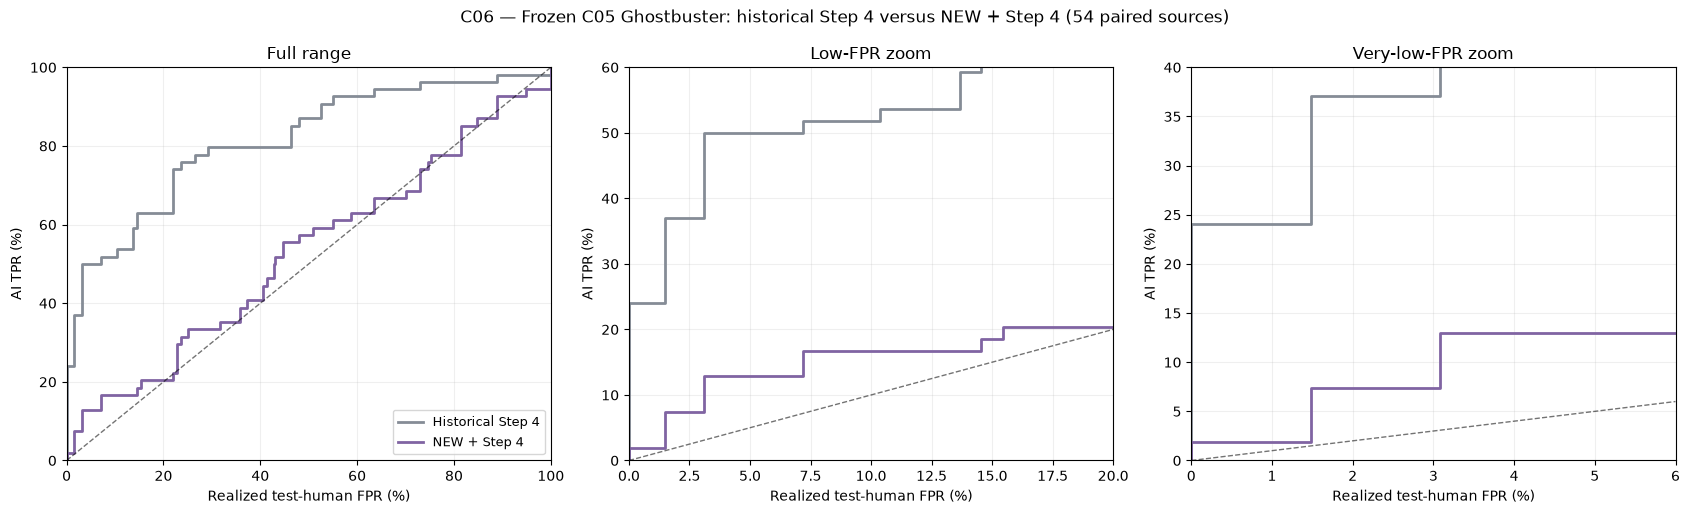

,requested_calibration_FPR,threshold,calibration_FPR,realized_test_FPR,Historical Step 4,NEW + Step 4
0,0.000,0.92422,0.00000,0.00000,0.14815,0.01852
1,0.001,0.92422,0.00000,0.00000,0.14815,0.01852
2,0.005,0.92422,0.00000,0.00000,0.14815,0.01852
3,0.010,0.81855,0.00842,0.00000,0.24074,0.01852
4,0.020,0.70800,0.01635,0.01488,0.37037,0.07407
5,0.030,0.70355,0.02561,0.01488,0.37037,0.07407
6,0.040,0.62080,0.03403,0.03087,0.50000,0.12963
7,0.050,0.57441,0.04990,0.07185,0.51852,0.12963
8,0.075,0.56238,0.06620,0.07185,0.51852,0.16667
9,0.100,0.53913,0.09240,0.07185,0.51852,0.16667


Lower NEW score: 43 /54 | Higher: 11
Figures: ../figures/C06_Ghostbuster_Step4_vs_NEW_Step4_TPR_staircase
Results: ../results/causal/C06_NEW_step4_Ghostbuster_v1
No C05 detector training, feature selection, or calibration changes were performed.


In [14]:
series={'Historical Step 4':old_scores,'NEW + Step 4':new_scores}
st=staircase(cal_scores,wc,human_scores,wh,series)
atomic_csv(st,OUT/'C06_Ghostbuster_Step4_vs_NEW_Step4_TPR_staircase.csv')
summary=pd.DataFrame([dict(stage=name,cases=len(s),
    AUROC=weighted_auc(human_scores,wh,s),mean_AI_score=float(np.mean(s)),
    median_AI_score=float(np.median(s))) for name,s in series.items()])
atomic_csv(summary,OUT/'stage_summary.csv');display(summary.round(6))
fig,axs=plt.subplots(1,3,figsize=(17,5.2))
panels=[((0,100),(0,100),'Full range'),((0,20),(0,60),'Low-FPR zoom'),
        ((0,6),(0,40),'Very-low-FPR zoom')]
for ax,(xlim,ylim,title) in zip(axs,panels):
    for (name,s),color in zip(series.items(),['#858C96','#8064A2']):
        ax.step(st.test_FPR*100,st[name]*100,where='post',lw=2,label=name,color=color)
    hi=min(xlim[1],ylim[1]);ax.plot([0,hi],[0,hi],'--',lw=1,alpha=.55,color='black')
    ax.set(xlim=xlim,ylim=ylim,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)',title=title)
    ax.grid(alpha=.2)
axs[0].legend(loc='lower right',fontsize=9)
fig.suptitle('C06 — Frozen C05 Ghostbuster: historical Step 4 versus NEW + Step 4 (54 paired sources)')
fig.tight_layout()
stem='C06_Ghostbuster_Step4_vs_NEW_Step4_TPR_staircase'
for folder in (OUT/'figures',FIG):
    for ext in ('pdf','png'):fig.savefig(folder/f'{stem}.{ext}',dpi=300,bbox_inches='tight')
plt.show();plt.close(fig)
# Budget table selects thresholds ONLY on weighted validation-human FPR.
budgets=np.unique(np.r_[0,.001,.005,.01,.02,.03,.04,.05,.075,.10,.15,.20,np.arange(.3,1.01,.1)])
operating=[]
for budget in budgets:
    eligible=st.loc[st.calibration_FPR<=budget+1e-12]
    r=eligible.iloc[-1]
    operating.append(dict(requested_calibration_FPR=float(budget),threshold=float(r.threshold),
        calibration_FPR=float(r.calibration_FPR),realized_test_FPR=float(r.test_FPR),
        **{name:float(r[name]) for name in series}))
operating=pd.DataFrame(operating)
atomic_csv(operating,OUT/'operating_points.csv');display(operating.round(5))
paired_scores=old_saved[['case_id','source_id','domain']].copy()
paired_scores['historical_step4_AI_score']=old_scores
paired_scores['NEW_step4_AI_score']=new_scores
paired_scores['NEW_minus_historical']=new_scores-old_scores
atomic_csv(paired_scores,OUT/'paired_AI_scores.csv')
print('Lower NEW score:',int((new_scores<old_scores).sum()),'/54 | Higher:',int((new_scores>old_scores).sum()))
print('Figures:',FIG/stem)
print('Results:',OUT)
print('No C05 detector training, feature selection, or calibration changes were performed.')


## Interpretation and handoff

The comparison changes the upstream generator/controller (historical input versus NEW) while applying the accepted downstream edit rules. Historical per-case target references are retained. This is a full-pipeline comparison, not a fresh ablation of M75 alone. No Ghostbuster score is consulted by the edit engine.

Use `manual_review.csv` to inspect edits, especially punctuation in recipes and the endings of token-capped NEW inputs. `editing_outcomes.csv` records residual targets and edit counts. Historical Step 4 and NFZ remain intact. NEW + Step 4 has not undergone Steps 5–10.

For a plotting-only rerun after shutdown, the saved staircase CSV and stage summary contain everything needed; no model loading is necessary.


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 160/160 [00:00<00:00, 4009.47it/s]
[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125M
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ada_surrogate_probs historical stream checks passed
ada_surrogate_probs: 1/54
ada_surrogate_probs: 2/54
ada_surrogate_probs: 3/54
ada_surrogate_probs: 4/54
ada_surrogate_probs: 5/54
ada_surrogate_probs: 6/54
ada_surrogate_probs: 7/54
ada_surrogate_probs: 8/54
ada_surrogate_probs: 9/54
ada_surrogate_probs: 10/54
ada_surrogate_probs: 11/54
ada_surrogate_probs: 12/54
ada_surrogate_probs: 13/54
ada_surrogate_probs: 14/54
ada_surrogate_probs: 15/54
ada_surrogate_probs: 16/54
ada_surrogate_probs: 17/54
ada_surrogate_probs: 18/54
ada_surrogate_probs: 19/54
ada_surrogate_probs: 20/54
ada_surrogate_probs: 21/54
ada_surrogate_probs: 22/54
ada_surrogate_probs: 23/54
ada_surrogate_probs: 24/54
ada_surrogate_probs: 25/54
ada_surrogate_probs: 26/54
ada_surrogate_probs: 27/54
ada_surrogate_probs: 28/54
ada_surrogate_probs: 29/54
ada_surrogate_probs: 30/54
ada_surrogate_probs: 31/54
ada_surrogate_probs: 32/54
ada_surrogate_probs: 33/54
ada_surrogate_probs: 34/54
ada_surrogate_probs: 35/54
ada_surrogat

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 316/316 [00:00<00:00, 1038.75it/s]
[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-1.3B
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
transformer.h.{0...23}.attn.attention.masked_bias | UNEXPECTED |  | 
transformer.h.{0...22}.attn.attention.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


davinci_surrogate_probs historical stream checks passed
davinci_surrogate_probs: 1/54
davinci_surrogate_probs: 2/54
davinci_surrogate_probs: 3/54
davinci_surrogate_probs: 4/54
davinci_surrogate_probs: 5/54
davinci_surrogate_probs: 6/54
davinci_surrogate_probs: 7/54
davinci_surrogate_probs: 8/54
davinci_surrogate_probs: 9/54
davinci_surrogate_probs: 10/54
davinci_surrogate_probs: 11/54
davinci_surrogate_probs: 12/54
davinci_surrogate_probs: 13/54
davinci_surrogate_probs: 14/54
davinci_surrogate_probs: 15/54
davinci_surrogate_probs: 16/54
davinci_surrogate_probs: 17/54
davinci_surrogate_probs: 18/54
davinci_surrogate_probs: 19/54
davinci_surrogate_probs: 20/54
davinci_surrogate_probs: 21/54
davinci_surrogate_probs: 22/54
davinci_surrogate_probs: 23/54
davinci_surrogate_probs: 24/54
davinci_surrogate_probs: 25/54
davinci_surrogate_probs: 26/54
davinci_surrogate_probs: 27/54
davinci_surrogate_probs: 28/54
davinci_surrogate_probs: 29/54
davinci_surrogate_probs: 30/54
davinci_surrogate_probs

,stage,cases,AUROC,mean_AI_score,median_AI_score
0,NEW,54,0.755985,0.453842,0.435328
1,NS4 — NEW + Steps 2–4,54,0.535734,0.269410,0.209114


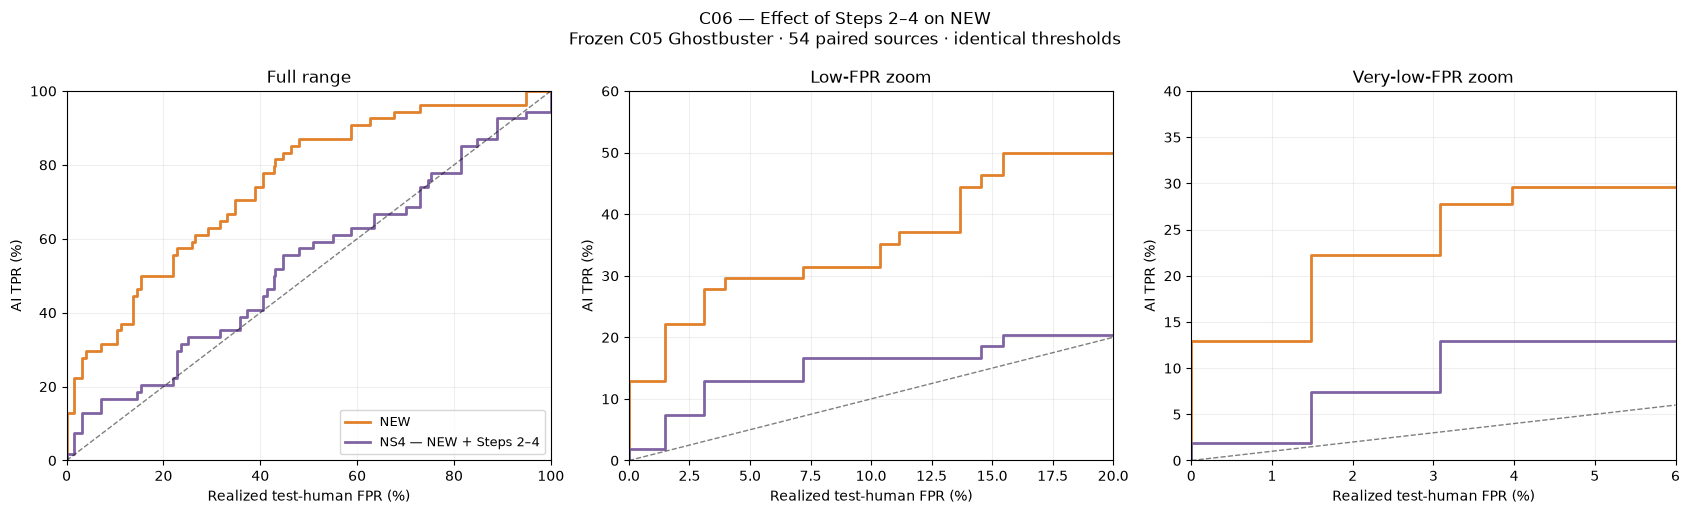

Steps 2–4 lowered AI score: 54/54 | Raised: 0 | Unchanged: 0
Mean score change (NS4 − NEW): -0.184431
Lower staircase / AUROC indicates reduced frozen-detector separability.


In [15]:
# C06 ablation: NEW versus NEW + Steps 2–4 (NS4)
# Uses the existing frozen C05 detector and identical human thresholds.

raw_new = NEW.set_index("case_id").loc[CASES].reset_index().copy()
ns4 = new_scored.set_index("case_id").loc[CASES].reset_index().copy()
assert len(raw_new) == len(ns4) == 54
assert raw_new.source_id.tolist() == ns4.source_id.tolist()
raw_new["text_sha"] = raw_new.text.map(sha_text)

# Reuse the existing resumable stream scorer for the raw NEW documents.
_saved_unique_docs = unique_docs
try:
    unique_docs = raw_new[["text_sha", "text"]].drop_duplicates("text_sha")

    with run_lock():
        ada_map.update(
            new_neural_stream(
                ADA_SURROGATE, "ada_surrogate_probs", old_ada
            )
        )
        dav_map.update(
            new_neural_stream(
                DAVINCI_SURROGATE, "davinci_surrogate_probs", old_dav
            )
        )

        for i, r in enumerate(unique_docs.itertuples(index=False), 1):
            spec = stream_spec(r.text_sha, "ngrams")
            path = stream_path(r.text_sha, "ngrams")
            value = read_record(path, spec)
            if value is None:
                if r.text_sha in old_ng.index:
                    value = dict(
                        trigram=list(old_ng.loc[r.text_sha, "trigram"]),
                        unigram=list(old_ng.loc[r.text_sha, "unigram"]),
                    )
                else:
                    tri, uni = gb_ngram_streams(r.text)
                    value = dict(trigram=tri, unigram=uni)
                write_record(path, spec, value)
            tri_map[r.text_sha] = value["trigram"]
            uni_map[r.text_sha] = value["unigram"]

        rows = []
        for r in raw_new.itertuples(index=False):
            v = ghostbuster_vector(r.text, r.text_sha)
            assert v.shape == (len(FEATURE_NAMES),)
            assert np.isfinite(v).all(), r.case_id
            rows.append(dict(
                case_id=r.case_id, source_id=r.source_id,
                domain=r.domain, text_sha=r.text_sha,
                **dict(zip(FEATURE_NAMES, v)),
            ))

        raw_features = pd.DataFrame(rows)
        raw_scores = frozen_predict(raw_features)
        raw_scored = raw_features[
            ["case_id", "source_id", "domain", "text_sha"]
        ].copy()
        raw_scored["AI_score"] = raw_scores
        atomic_csv(raw_features, OUT / "NEW_raw_features.csv")
        atomic_csv(raw_scored, OUT / "NEW_raw_scores.csv")
finally:
    unique_docs = _saved_unique_docs

assert all(
    file_sha(ROOT / p) == h for p, h in FROZEN_HASHES.items()
), "A frozen C05 artifact changed."

# Same calibration thresholds and test-human weights as the existing C06 plot.
ablation_series = {
    "NEW": raw_scores,
    "NS4 — NEW + Steps 2–4": ns4.AI_score.to_numpy(),
}
ablation_st = staircase(
    cal_scores, wc, human_scores, wh, ablation_series
)
atomic_csv(ablation_st, OUT / "NEW_vs_NS4_TPR_staircase.csv")

ablation_summary = pd.DataFrame([
    dict(
        stage=name, cases=len(scores),
        AUROC=weighted_auc(human_scores, wh, scores),
        mean_AI_score=float(np.mean(scores)),
        median_AI_score=float(np.median(scores)),
    )
    for name, scores in ablation_series.items()
])
display(ablation_summary.round(6))
atomic_csv(ablation_summary, OUT / "NEW_vs_NS4_summary.csv")

fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
panels = [
    ((0, 100), (0, 100), "Full range"),
    ((0, 20), (0, 60), "Low-FPR zoom"),
    ((0, 6), (0, 40), "Very-low-FPR zoom"),
]
for ax, (xlim, ylim, title) in zip(axs, panels):
    for (name, scores), color in zip(
        ablation_series.items(), ["#E1812C", "#8064A2"]
    ):
        ax.step(
            ablation_st.test_FPR * 100,
            ablation_st[name] * 100,
            where="post", lw=2, color=color, label=name,
        )
    hi = min(xlim[1], ylim[1])
    ax.plot([0, hi], [0, hi], "--", color="black", alpha=.5, lw=1)
    ax.set(
        xlim=xlim, ylim=ylim, title=title,
        xlabel="Realized test-human FPR (%)", ylabel="AI TPR (%)",
    )
    ax.grid(alpha=.2)

axs[0].legend(loc="lower right", fontsize=9)
fig.suptitle(
    "C06 — Effect of Steps 2–4 on NEW\n"
    "Frozen C05 Ghostbuster · 54 paired sources · identical thresholds"
)
fig.tight_layout()
for folder in (OUT / "figures", FIG):
    folder.mkdir(parents=True, exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(
            folder / f"C06_NEW_vs_NS4_TPR_staircase.{ext}",
            dpi=300, bbox_inches="tight",
        )
plt.show()
plt.close(fig)

paired_ablation = raw_scored[["case_id", "domain"]].copy()
paired_ablation["NEW_AI_score"] = raw_scores
paired_ablation["NS4_AI_score"] = ns4.AI_score.to_numpy()
paired_ablation["NS4_minus_NEW"] = (
    paired_ablation.NS4_AI_score - paired_ablation.NEW_AI_score
)
atomic_csv(paired_ablation, OUT / "NEW_vs_NS4_paired_scores.csv")

delta = paired_ablation.NS4_minus_NEW
print(
    f"Steps 2–4 lowered AI score: {(delta < 0).sum()}/54 | "
    f"Raised: {(delta > 0).sum()} | Unchanged: {(delta == 0).sum()}"
)
print(f"Mean score change (NS4 − NEW): {delta.mean():+.6f}")
print("Lower staircase / AUROC indicates reduced frozen-detector separability.")